## Fresh comparison: WERM+P ($\gamma=6$), WERM, charcoal, and McScan

Paper figures 14. Saved results are shown by default; enable the switches below to recompute.

In [1]:
from pathlib import Path
import os
if not Path("WERM").is_dir() and Path("../WERM").is_dir():
    os.chdir("..")
assert Path("WERM").is_dir(), "Open this notebook from the repository root."
from paper_support import show_panels
RUN_EXPERIMENTS = False
REGENERATE_FIGURES = False
REGENERATE_FIGURES = REGENERATE_FIGURES or RUN_EXPERIMENTS

if REGENERATE_FIGURES:
    import numpy as np, pickle, time, logging
    import matplotlib.pyplot as plt
    from IPython.display import display
    main_logger = logging.getLogger("paper")
    Path("figures").mkdir(exist_ok=True)


In [2]:
if RUN_EXPERIMENTS:
    def run_m2_fresh_four_method_comparison():
        import os
        import sys
        import time
        import pickle
        import hashlib
        from pathlib import Path
        from contextlib import redirect_stdout, redirect_stderr
        from io import StringIO
        paired_r = Path(sys.prefix) / 'lib' / 'R'
        if paired_r.is_dir():
            os.environ['R_HOME'] = str(paired_r)
        import numpy as np
        import jax
        import torch
        import WERM.config as config
        import WERM.comparison as competitors
        from WERM.signal_priors import SparseDiffSignal
        from WERM.model import q_linear_model
        from WERM.experiment_utils import trial_rng, data_hash, evaluate_changepoints, weighted_erm_joint_cv
        from WERM.estimators import weighted_erm
        from WERM.gof import manuscript_log_binomial_k_penalty
        from joblib import Parallel, delayed, parallel_config
        from joblib.externals.loky.process_executor import TerminatedWorkerError
        jax.config.update('jax_enable_x64', True)
        gamma = 6.0
        reference_path = Path('results/M2_upsample_final_alpha03_seed42_100trials.pkl')
        reference_bytes = reference_path.read_bytes()
        reference = pickle.loads(reference_bytes)
        params = {key: reference['params'][key] for key in ('p', 'L', 'num_trials', 'delta_list', 'fractional_chgpt_locations', 'fixed_noise_scale', 'random_seed')}
        (p, upper_L, trials) = (int(params['p']), int(params['L']), int(params['num_trials']))
        deltas = np.asarray(params['delta_list'])
        fractions = np.asarray(params['fractional_chgpt_locations'])
        noise_scale = float(params['fixed_noise_scale'])
        assert (p, upper_L, trials) == (200, 4, 100)
        assert np.array_equal(deltas, np.arange(0.5, 16.0, 1.0))
        curve_indices = list(range(len(deltas)))[1:-2:2]
        histogram_indices = []
        setting_indices = curve_indices
        charcoal_indices = [i for i in list(range(len(deltas)))[1:-2] if deltas[i] <= 9.0]
        all_indices = sorted(set(setting_indices) | set(charcoal_indices))
        methods = ('McScan', 'charcoal', 'WERM', 'WERM+P')
        params.update(methods_evaluated=[dict(name=method) for method in methods], num_folds_unpenalized=(10,), charcoal_threshold=float(competitors.CHARCOAL_THRESHOLD), charcoal_seed=int(competitors.CHARCOAL_SEED), charcoal_max_delta=9.0)
        reference_rows = {(int(i), int(j)): row for (i, j, row) in reference['results']['trial_records']}
        tasks = [(i, j) for i in all_indices for j in range(trials)]
        root = Path('results/M2_upsample_final_WERM_plus_P_gamma6_fresh')
        root.mkdir(parents=True, exist_ok=True)
        signature = dict(schema=1, experiment='fresh-four-method-gamma6', gamma=gamma, reference_sha256=hashlib.sha256(reference_bytes).hexdigest(), methods=methods, setting_indices=tuple(setting_indices), charcoal_indices=tuple(charcoal_indices), trials=trials, marginal_seed=0, r_seed=42, folds=10, charcoal_threshold=float(competitors.CHARCOAL_THRESHOLD), charcoal_seed=int(competitors.CHARCOAL_SEED), charcoal_max_delta=9.0, numpy_version=np.__version__, jax_version=jax.__version__)
        signature['source_sha256'] = {name: hashlib.sha256(Path(name).read_bytes()).hexdigest() for name in ('WERM/signal_priors.py', 'WERM/model.py', 'WERM/config.py', 'WERM/comparison.py', 'WERM/experiment_utils.py', 'WERM/estimators.py', 'WERM/proximal.py', 'WERM/gof.py')}

        def save_atomic(path, value):
            tmp = path.with_name(path.name + f'.tmp-{os.getpid()}')
            with tmp.open('wb') as handle:
                pickle.dump(value, handle, protocol=pickle.HIGHEST_PROTOCOL)
            os.replace(tmp, path)

        def load_checkpoint(i, j):
            path = root / f'setting_{i:02d}_trial_{j:03d}.pkl'
            if path.exists():
                with path.open('rb') as handle:
                    payload = pickle.load(handle)
                row = payload['row']
                if payload.get('signature') == signature and (row['setting'], row['trial']) == (i, j) and (row['data_hash'] == reference_rows[i, j]['data_hash']):
                    return row
            return None

        def trial(i, j):
            cached = load_checkpoint(i, j)
            if cached is not None:
                return cached
            delta = float(deltas[i])
            n = int(delta * p)
            rng = trial_rng('M2c-alpha-0.3', i, j)
            B = SparseDiffSignal(8, np.sqrt(400 * delta), 0.3, upper_L).sample(p, rng=rng)
            X = rng.normal(0, np.sqrt(1 / n), (n, p))
            noise = rng.normal(0, 1, size=n) * noise_scale
            X = X @ np.linalg.cholesky(np.eye(p)).T
            X_scaled = X * np.sqrt(n)
            truth = (n * fractions).astype(int)
            theta = X_scaled @ (B / np.sqrt(n))
            y = np.asarray(jax.vmap(q_linear_model, in_axes=(0, 0, 0))(theta, config.η_to_ψ(truth, n), noise))
            fingerprint = data_hash(X, y)
            assert fingerprint == reference_rows[i, j]['data_hash'], (i, j, 'data hash mismatch')
            (estimates, diagnostics) = ({}, {})

            def record(name, cp, elapsed):
                estimates[name] = dict(runtime=float(elapsed), **evaluate_changepoints(cp, truth, n))
            with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
                if i in setting_indices:
                    competitors.ro.r['set.seed'](42)
                    start = time.perf_counter()
                    cp = competitors.run_mcscan(X_scaled, y.flatten(), num_chgpts=None, method='auto')
                    record('McScan', cp, time.perf_counter() - start)
                if delta <= 9.0:
                    start = time.perf_counter()
                    try:
                        cp = competitors.run_charcoal(X_scaled, y)
                    except competitors.rpy2.rinterface_lib.embedded.RRuntimeError as exc:
                        diagnostics['charcoal_R_error'] = str(exc)
                        cp = np.array([], dtype=int)
                    record('charcoal', cp, time.perf_counter() - start)
                else:
                    record('charcoal', None, np.nan)
                    diagnostics['charcoal'] = 'not applicable above delta=9'
            row = dict(setting=i, trial=j, n=n, true_cp=truth, data_hash=fingerprint, estimates=estimates, diagnostics=diagnostics)
            if i in setting_indices:
                original_marginals = config.extrapolated_marginals
                marginal_cache = {}

                def shared_marginals(Lmin, Lmax, Delta_small, n_small=50, n_large=1000, p_l=None, verbose='summary'):
                    prior = None if p_l is None else tuple(np.asarray(p_l).tolist())
                    key = (int(Lmin), int(Lmax), int(Delta_small), int(n_small), int(n_large), prior)
                    if key not in marginal_cache:
                        (numpy_state, torch_state) = (np.random.get_state(), torch.random.get_rng_state())
                        try:
                            np.random.seed(0)
                            torch.manual_seed(0)
                            marginal_cache[key] = original_marginals(Lmin, Lmax, Delta_small, n_small=n_small, n_large=n_large, p_l=p_l, verbose=False)
                        finally:
                            np.random.set_state(numpy_state)
                            torch.random.set_rng_state(torch_state)
                    return marginal_cache[key].copy()
                loss = lambda u, v: (np.asarray(u) - np.asarray(v)) ** 2
                scorer = lambda u, v: np.abs(np.asarray(u) - np.asarray(v))
                config.extrapolated_marginals = shared_marginals
                try:
                    with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
                        prep_start = time.perf_counter()
                        sample_sizes = {n} | {n - len(np.arange(f, n, 10)) for f in range(10)}
                        for length in sorted(sample_sizes):
                            separation = max(int(np.ceil(length / 50)), int(length / 40), 1)
                            for k in range(1, upper_L + 1):
                                shared_marginals(k, k, int(separation * 50 / length), n_small=50, n_large=length, verbose=False)
                        row['marginal_preparation_seconds'] = time.perf_counter() - prep_start
                        start = time.perf_counter()
                        ((cv_k, _), cv_cp, cv_diagnostics) = weighted_erm_joint_cv(X=X, y=y, M=loss, M_scorer=scorer, Lmax=upper_L, delta_fraction=1 / 40, l1_constants=(0.0,), num_folds=10, n_jobs=1, standardize_y=False, selection_strategy='exhaustive', penalty_norm='none', coefficient_loss='least_squares', return_diagnostics=True)
                        record('WERM', cv_cp, time.perf_counter() - start)
                        start = time.perf_counter()
                        (candidates, raw) = ({}, [])
                        separation = max(int(np.ceil(n / 50)), int(n / 40), 1)
                        for k in range(1, upper_L + 1):
                            (cp, objective) = weighted_erm(X=X, y=y, M=loss, L=k, Delta_n=separation, gamma=0.0, L_is_upper_bound=False, return_gof=True, coefficient_loss='least_squares', coefficient_penalty='none', coefficient_lambda=0.0)
                            candidates[k] = np.asarray(cp, dtype=int)
                            raw.append(float(objective))
                        penalty = manuscript_log_binomial_k_penalty(n, gamma)
                        objectives = np.asarray(raw) + np.array([penalty(k) for k in range(1, upper_L + 1)])
                        selected_k = 1 + int(np.argmin(objectives))
                        record('WERM+P', candidates[selected_k], time.perf_counter() - start)
                        assert np.array_equal(candidates[int(cv_k)], cv_cp), (i, j, cv_k)
                        row.update(cv_K=int(cv_k), penalty_K=selected_k, raw_by_K=np.asarray(raw), cp_by_K=candidates, cv_diagnostics=cv_diagnostics, cv_fixed_count_match=True, penalty_objectives=objectives)
                finally:
                    config.extrapolated_marginals = original_marginals
            save_atomic(root / f'setting_{i:02d}_trial_{j:03d}.pkl', dict(signature=signature, row=row))
            return row
        completed = {}
        for (i, j) in tasks:
            cached = load_checkpoint(i, j)
            if cached is not None:
                completed[i, j] = cached
        jobs = max(1, int(os.environ.get('M2_FRESH_JOBS', '24')))
        crashes = 0
        while len(completed) < len(tasks):
            pending = [(i, j) for (i, j) in tasks if (i, j) not in completed]
            try:
                with parallel_config(backend='loky', inner_max_num_threads=1):
                    stream = Parallel(n_jobs=min(jobs, len(pending)), batch_size=1, pre_dispatch=jobs, return_as='generator_unordered')((delayed(trial)(i, j) for (i, j) in pending))
                    for row in stream:
                        completed[row['setting'], row['trial']] = row
                        if len(completed) % 20 == 0 or len(completed) == len(tasks):
                            pass
            except TerminatedWorkerError:
                crashes += 1
                for (i, j) in pending:
                    cached = load_checkpoint(i, j)
                    if cached is not None:
                        completed[i, j] = cached
                if crashes > 3:
                    raise
                jobs = max(1, jobs // 2)
        rows = [completed[key] for key in tasks]
        metrics = {name: {metric: np.full((len(deltas), trials), np.nan) for metric in ('haus', 'size', 'runtime')} for name in methods}
        for row in rows:
            for (method, result) in row['estimates'].items():
                for metric in ('haus', 'size', 'runtime'):
                    metrics[method][metric][row['setting'], row['trial']] = result[metric]
        paired = [row for row in rows if row['setting'] in setting_indices]
        same_count = [row for row in paired if row['cv_K'] == row['penalty_K']]
        exact = sum((np.array_equal(row['estimates']['WERM']['raw_cp'], row['estimates']['WERM+P']['raw_cp']) for row in same_count))
        assert exact == len(same_count)
        comparison = dict(signature=signature, params=params, gamma=gamma, methods=methods, trial_records=rows, metrics=metrics, setting_indices=setting_indices, charcoal_indices=charcoal_indices, curve_indices=curve_indices, histogram_indices=histogram_indices, conditional_location_audit=dict(same_count=len(same_count), identical_locations=exact), charcoal_R_errors=sum(('charcoal_R_error' in row['diagnostics'] for row in rows)))
        save_atomic(root / 'comparison.pkl', comparison)
        return comparison
    m2_fresh_comparison = run_m2_fresh_four_method_comparison()


## Updated consistent plots

In [3]:
if REGENERATE_FIGURES:
    from tools.consistent_plotting import *
    plt.close("all")


### Completed fresh four-method comparison, gamma = 6

In [4]:
if REGENERATE_FIGURES:
    saved = load_saved('results/M2_upsample_final_WERM_plus_P_gamma6_fresh/comparison.pkl')
    params = saved['params']
    deltas = np.asarray(params['delta_list'])
    truth = np.asarray(params['fractional_chgpt_locations'])
    methods = ['McScan', 'charcoal', 'WERM', 'WERM+P']
    METHODS['WERM'] = ('\\textbf{WERM+CV}', 'black', 'D', '-')
    METHODS['WERM+P'] = ('\\textbf{WERM+P}', '#228833', 'h', '-')
    records = saved['trial_records']
    failed = {(r['setting'], r['trial']) for r in records if 'charcoal_R_error' in r.get('diagnostics', {})}
    assert len(failed) == saved['charcoal_R_errors'] == 4
    assert len({(r['setting'], r['trial']) for r in records}) == len(records)
    for method in methods:
        indices = saved['charcoal_indices'] if method == 'charcoal' else saved['setting_indices']
        entries = [r['estimates'][method] for r in records if r['setting'] in indices and method in r['estimates']]
        assert len(entries) == 100 * len(indices)
        for i in indices:
            assert {r['trial'] for r in records if r['setting'] == i and method in r['estimates']} == set(range(100))
        errors = [e for e in entries if e['raw_cp'] is None]
        r_failures = len(failed) if method == 'charcoal' else 0
        for e in entries:
            if e['raw_cp'] is None:
                assert not np.isfinite(e['haus'])
            elif e['size'] == 0:
                assert not np.isfinite(e['haus'])
    with plt.rc_context(PAPER_STYLE):
        for (metric, ylabel) in [('haus', 'Hausdorff dist. / $n$'), ('size', 'No. change points'), ('runtime', 'Runtime (s)')]:
            for kind in ('line',):
                (fig, ax) = paper_panel()
                rng = np.random.default_rng(42)
                handles = []
                for (j, method) in enumerate(methods):
                    (label, color, marker, ls) = METHODS[method]
                    indices = saved['charcoal_indices'] if method == 'charcoal' else saved['curve_indices']
                    source = np.asarray(saved['metrics'][method][metric]).copy()
                    if method == 'charcoal':
                        for (setting, trial) in failed:
                            source[setting, trial] = np.nan
                    values = source[indices]
                    if kind == 'line':
                        error_series(ax, deltas[indices], values, label, color, marker, ls)
                    else:
                        for (i, v) in zip(indices, values):
                            box_group(ax, v, float(deltas[i]) + (j - 1.5) * 0.17, color, rng, width=0.14, jitter=0.055)
                        handles.append(Patch(facecolor=color, alpha=0.28, edgecolor='black', label=label))
                ax.set(xlabel='$\\delta=n/p$', ylabel=ylabel)
                ax.set_xticks(deltas[saved['curve_indices']][::2])
                if metric == 'size':
                    ax.axhline(2, color='gray', lw=2.5 * SCALE, alpha=0.8, zorder=0)
                    ax.yaxis.set_major_locator(MaxNLocator(4, integer=True))
                    ax.set_ylim(0, 5)
                if metric == 'runtime':
                    ax.legend(handles=handles if kind == 'box' else None, loc='best', prop={'size': 8}, fancybox=True, frameon=True, framealpha=0.4)
                export_plot(fig, f'M2_fresh_{metric}_{kind}')
    plt.close("all")


## Figure 14

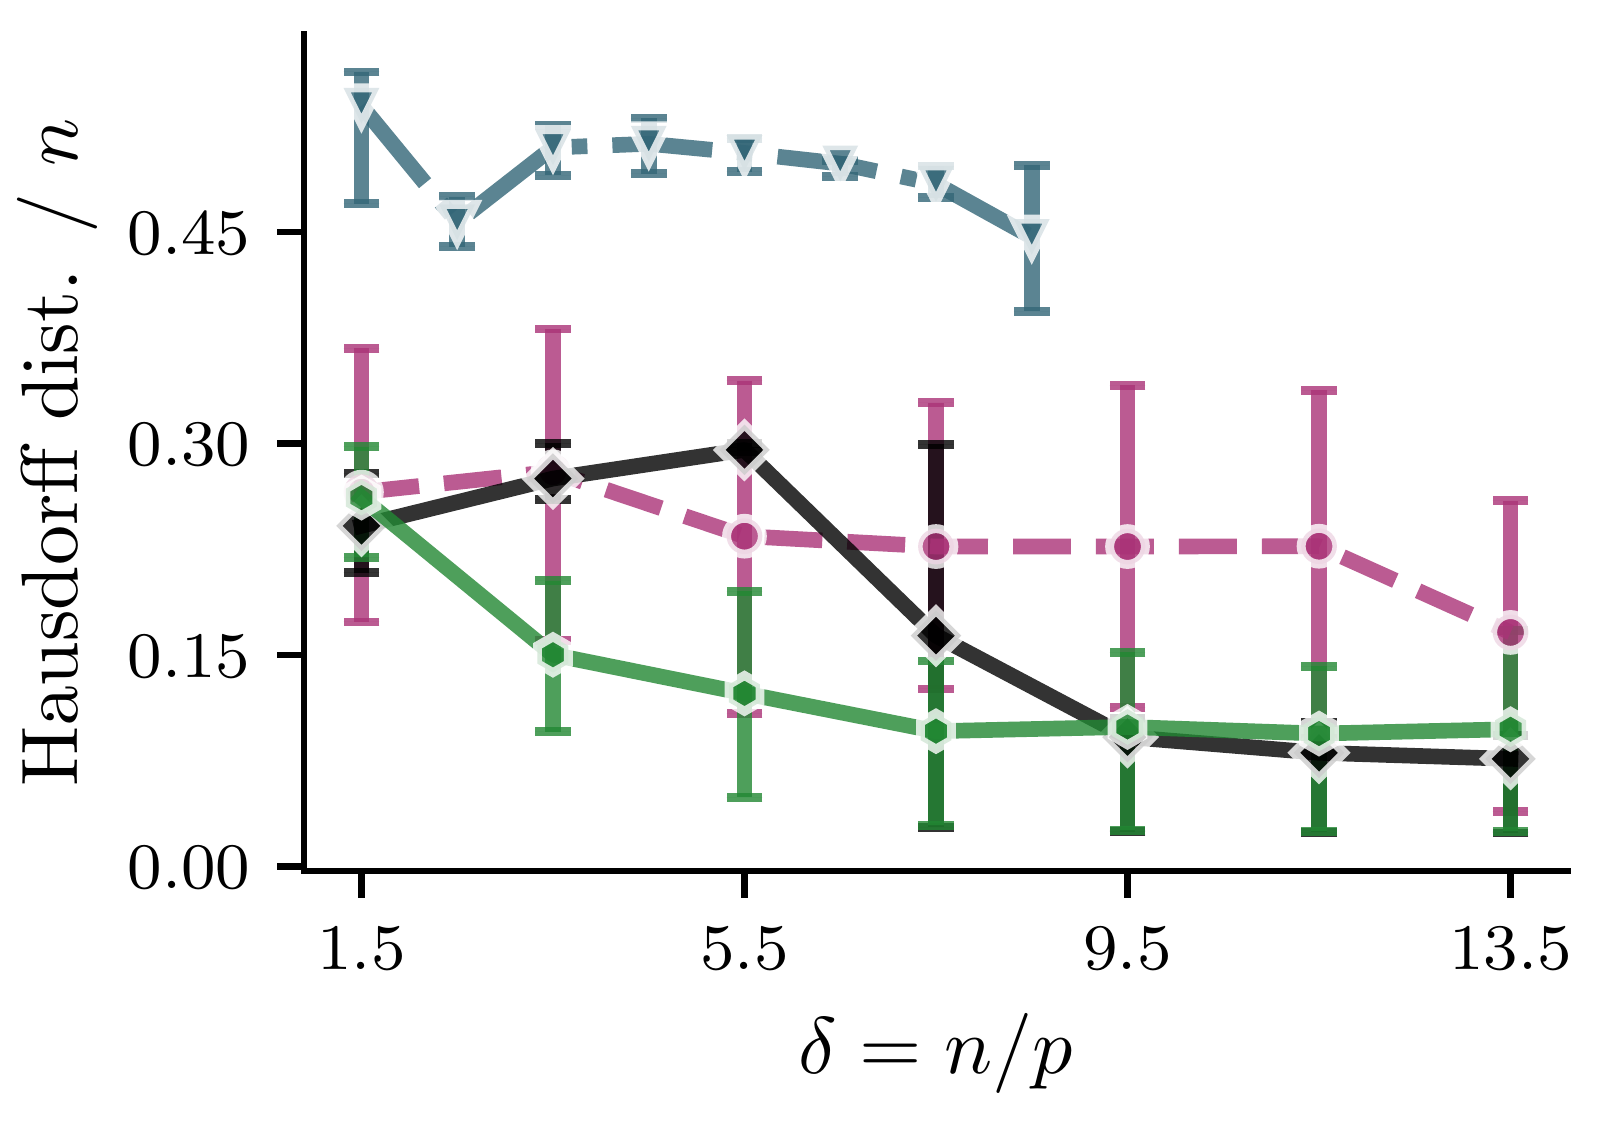

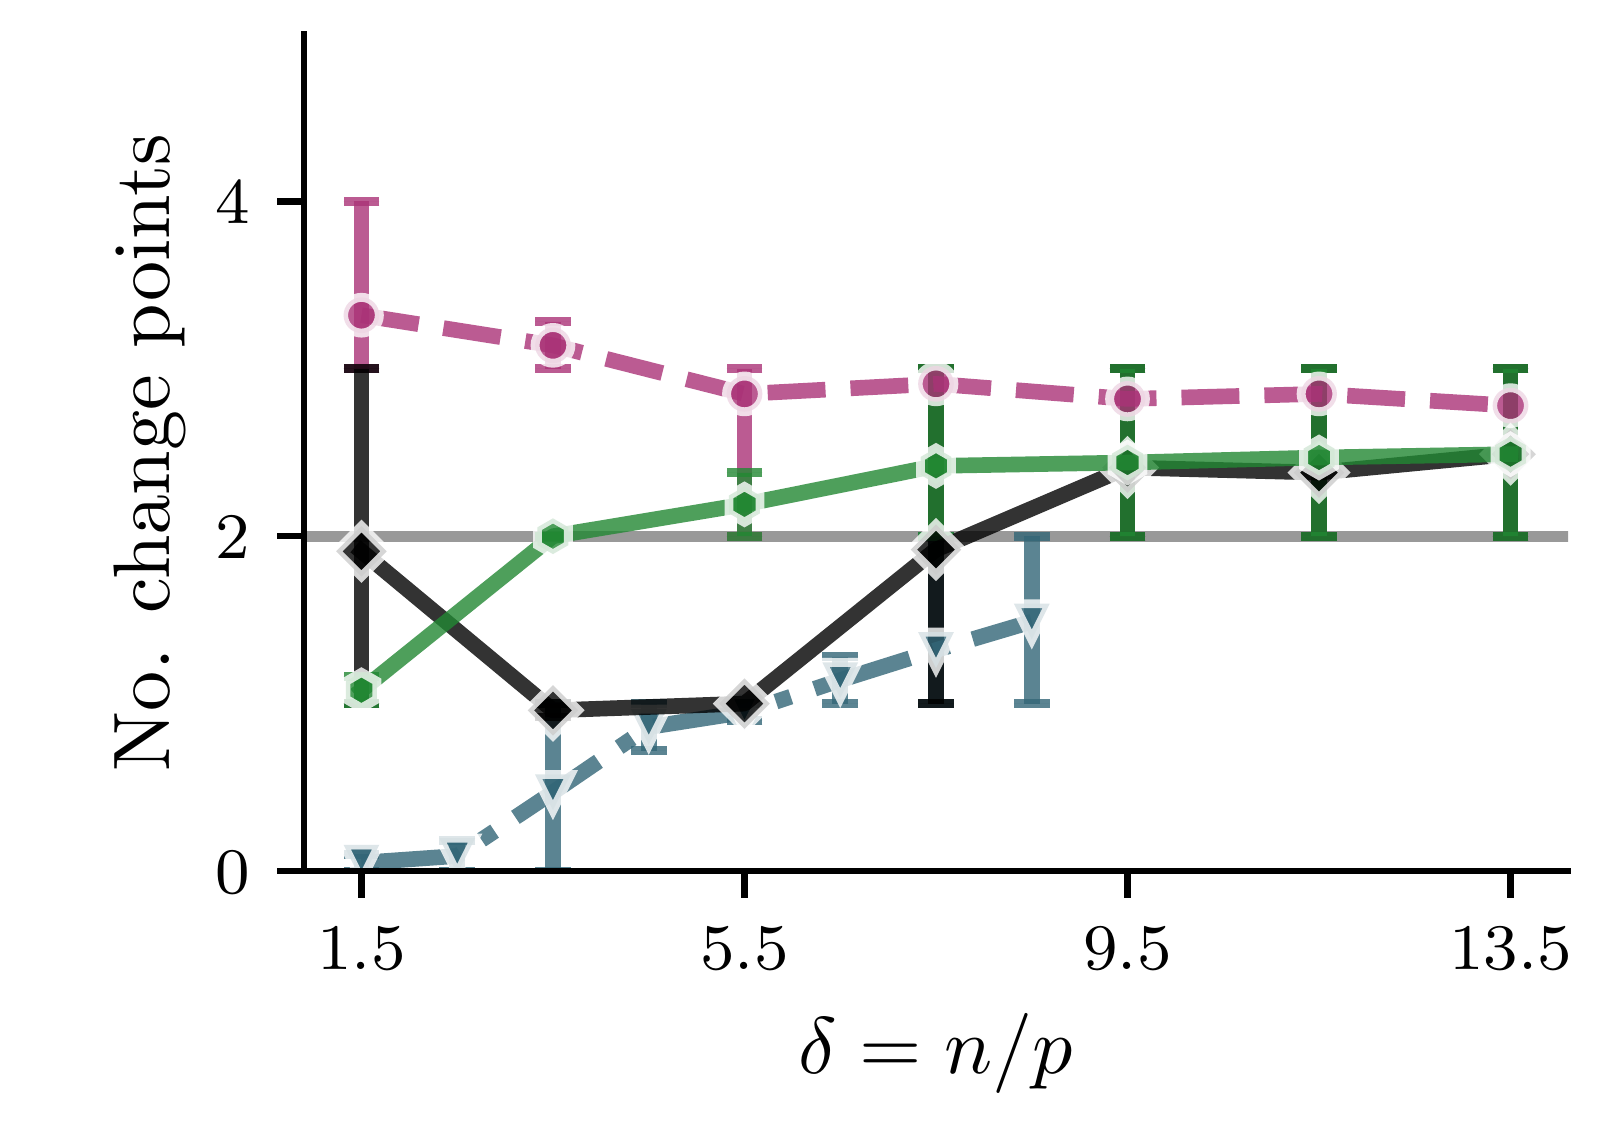

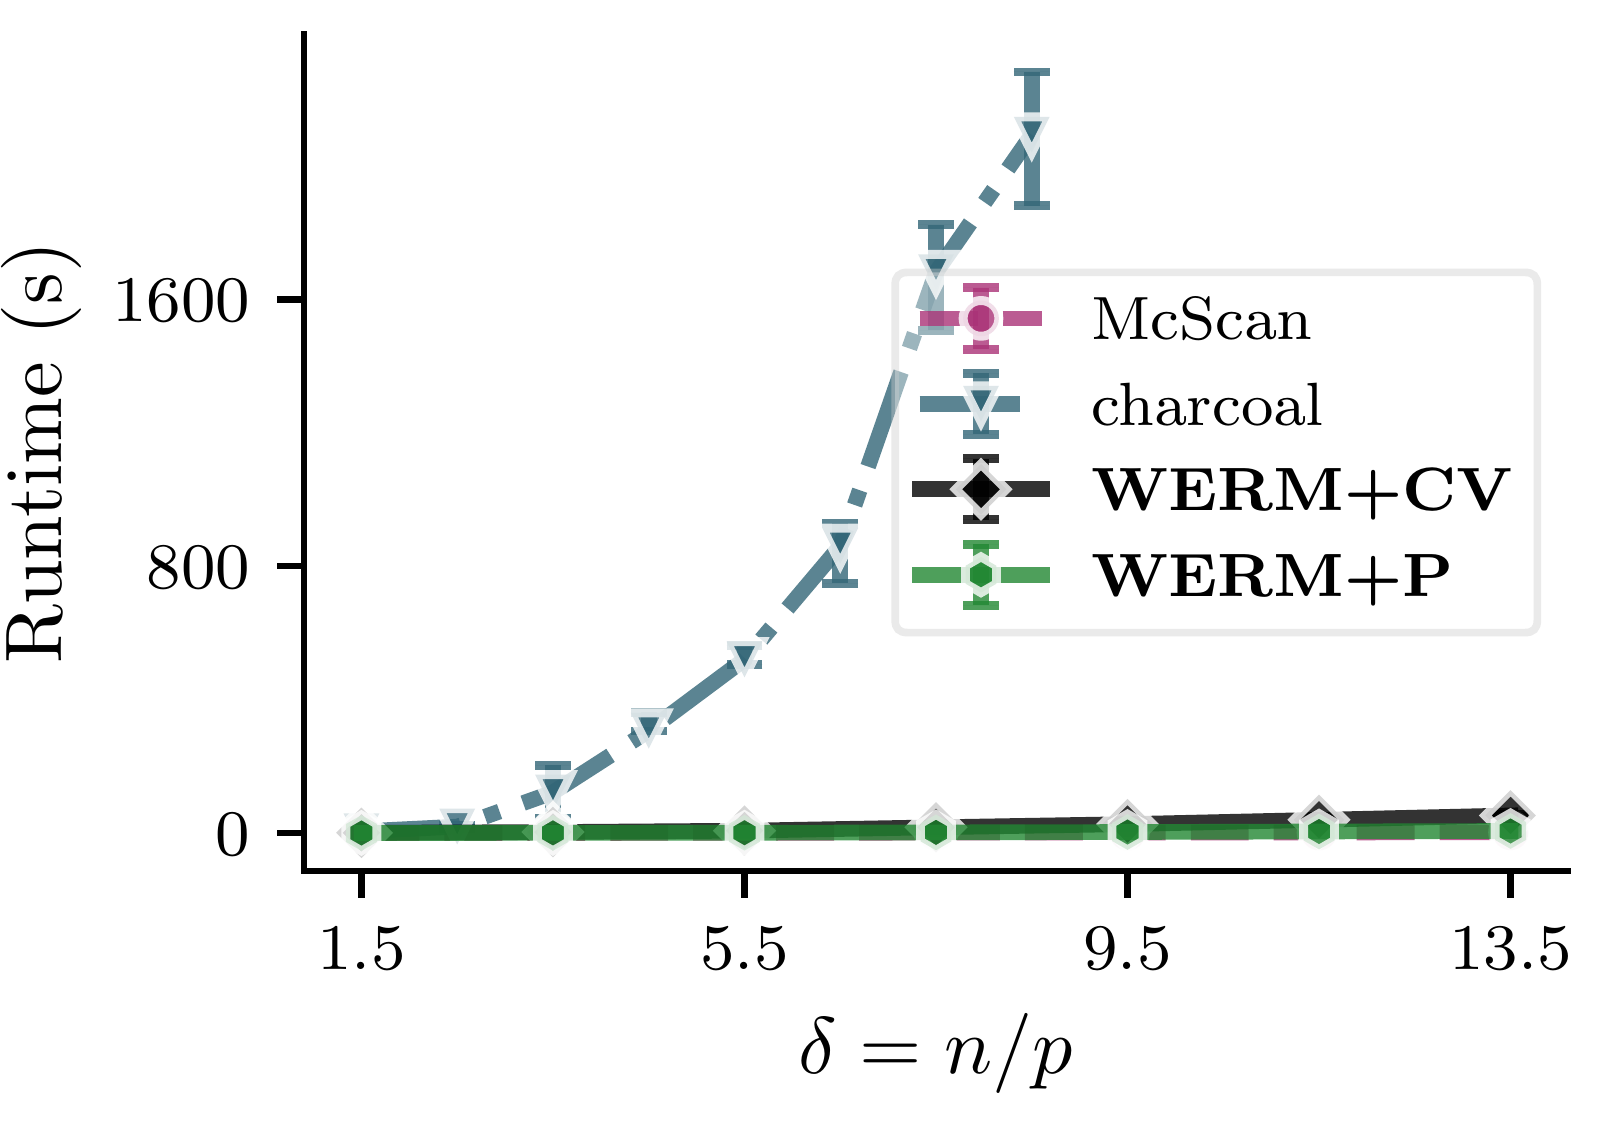

In [5]:
panels = ['figures/regenerated/M2_fresh_haus_line.pdf', 'figures/regenerated/M2_fresh_size_line.pdf', 'figures/regenerated/M2_fresh_runtime_line.pdf'] if REGENERATE_FIGURES else ['figures/figure_14/panel_01.pdf', 'figures/figure_14/panel_02.pdf', 'figures/figure_14/panel_03.pdf']
show_panels(panels)
